<a id="top"></a>

![STScI Logo](../../../_static/stsci_header.png)

# `Slitlessutils` Cookbook: Spectral Extraction for WFC3/IR

This notebook contains a step-by-step guide for performing spectral extractions with Slitlessutils for G102 (or G141) data from WFC3/IR.<br>
The original source for this notebook is the WFC3 folder on the [spacetelescope/hst_notebooks](https://github.com/spacetelescope/hst_notebooks) GitHub repository.

***
## Learning Goals
In this tutorial, you will:
- Configure `slitlessutils`
- Download data
- Calibrate grism data with custom background subtraction code `back_sub.py`
- Preprocess data for extraction
- Extract 1-D spectra with a simple box extraction

## Table of Contents

[1. Introduction](#intro) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.1 Environment](#env) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2 Imports](#import) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.3 Slitlessutils Configuration](#config) <br>
[2. Define Global Variables](#globalvar) <br>
[3. Download Data](#download) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[3.1 Create Data Directories and Organize](#organize)<br>
[4. Calibrate Data](#cal)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4.1 Run WFC3 Backsub on Grism Data](#backsub)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4.2 Check the World Coordinate System (WCS)](#checkwcs)<br>
[5. Preprocess the F105W Direct Images](#direct)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[5.1 Display Drizzle Image and Overlay Segmentation Map](#drizzle)<br>
[6. Extract the Spectra from the Grism Data](#extract)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[6.1 Display a Region File](#region)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[6.2 Plot the Spectrum](#plot)<br>
[7. Conclusions](#conclusions) <br>
[Additional Resources](#add) <br>
[About this Notebook](#about) <br>
[Citations](#cite) <br>


<a id="intro"></a>
## 1. Introduction 

[Slitlessutils](https://github.com/spacetelescope/slitlessutils) is an official STScI-supported Python package that provides spectral extraction processes for HST grism and <br>
prism data. The `slitlessutils` software package has formally replaced the [HSTaXe](https://github.com/spacetelescope/hstaxe) Python package, which will remain<br>
on the [spacetelescope](https://github.com/spacetelescope/) GitHub organization, but no longer be maintained or developed. 

Below, we show an example workflow of spectral extraction using WFC3/IR G102 grism data and F105W direct image data. <br>
The example data were taken as part of WFC3 CAL program [17687](https://www.stsci.edu/hst-program-info/program/?program=17687) and are downloaded from the Mikulski Archive for Space <br>Telescopes (MAST) via `astroquery`. The images are all full-frame exposures. Users with subarray data will need to employ <br>
the [embedding](https://github.com/spacetelescope/slitlessutils/blob/fdc136156e0a47212bdabba07a0f4c865c839f99/slitlessutils/core/utilities/embedding.py) utility within `slitlessutils` before processing and extracting the data. See the UVIS [subarray cookbook](https://github.com/spacetelescope/hst_notebooks/tree/main/notebooks/WFC3) <br>
for a tutorial on using `slitlessutils` with subarray data. This tutorial is intended to run continuously without requiring any <br>edits to the cells. 

Running this notebook requires creating a `conda` environment from the provided requirements file in this notebook's sub-folder <br>
in the GitHub repository. For more details about creating the necessary environment, see the [next section](#env).

To run `slitlessutils`, we must download the configuration reference files. These files are instrument-specific and include <br>
sensitivity curves, trace and dispersion files, flat fields, and more. `Slitlessutils` has a `Config` class with an associated <br>
function that will download the necessary reference files from a Box folder. [Section 1.3](#config) shows how to use `slitlessutils` <br>
to retrieve the files. Once downloaded, `slitlessutils` will use them for the different processes.


Finally, due to the multi-component nature of the WFC3/IR background, we recommend users consider calibrating RAW <br>
G102/G141 FITS files with the WFC3 Backsub program. This type of complex background subtraction is not available within <br>
`slitlessutils` and can have a noticeable impact on science results. All necessary files are available [on Box](https://stsci.box.com/s/xrz16v1tv58y8vcfy8zlrn83jrpnam19), and in <br>
[Section 4.1](#backsub) of this notebook, we download the Backsub files with Python and demonstrate how to run the program. 


<a id="env"></a>
### 1.1 Environment 

This notebook requires users to install the packages listed in the `requirements.txt` file located in the notebook's <br>
sub-folder on the GitHub repository. We will use the `conda` package manager to build the necessary virtual environment. <br>
For more information about installing and getting started with Conda (or Mamba), please see [this page](https://stenv.readthedocs.io/en/latest/getting_started.html#getting-started). <br>

First, we will make sure the `conda-forge` channel is added so that `conda` can correctly find the various packages. <br>
`$ conda config --add channels conda-forge`

Next, we will create a new environment called `slitlessutils` and initialize it with `hstcal` and `python`: <br>
`$ conda create --name slitlessutils "hstcal==3.1.0" "python==3.12" `

Wait for `conda` to solve for the environment and confirm the packages/libraries with the `y` key when prompted. <br>
Once completed, you can activate the new environment with:<br>
`$ conda activate slitlessutils`

With the new environment activated, we can install the remaining packages from the `requirements.txt` file with `pip`: <br>
`$ pip install -r requirements.txt`

Note, you may encounter an error installing `llvmlite`. To fix it, run the below command before installing `slitlessutils`: <br>
`$ conda install -c conda-forge llvmlite`

We have now successfully installed all the necessary packages for running this notebook. Launch Jupyter and begin: <br>
`$ jupyter-lab` 


<a id="import"></a>
### 1.2 Imports 
    
For this notebook we import:

<table style="margin-left: 0; margin-right: auto; border-collapse: collapse;">
  <thead>
    <tr>
      <th style="text-align: left; padding: 6px;">Package</th>
      <th style="text-align: left; padding: 6px;">Purpose</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 6px;"><code>glob</code></td>
      <td style="padding: 6px;">File handling</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>matplotlib.pyplot</code></td>
      <td style="padding: 6px;">Displaying images and plotting spectrum</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>numpy</code></td>
      <td style="padding: 6px;">Handling arrays</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>os</code></td>
      <td style="padding: 6px;">System commands</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>requests</code></td>
      <td style="padding: 6px;">Stream download of the WFC3 Backsub tar.gz from Box</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>shutil</code></td>
      <td style="padding: 6px;">File and directory clean up</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>tarfile</code></td>
      <td style="padding: 6px;">Extract the downloaded WFC3 Backsub .tar.gz </td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>astropy.io.fits</code></td>
      <td style="padding: 6px;">Reading and modifying/creating FITS files</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>astropy.visualization</code></td>
      <td style="padding: 6px;">Various tools for display FITS images</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>astropy.wcs.WCS</code></td>
      <td style="padding: 6px;">Handling WCS objects</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>astroquery.mast.Observations</code></td>
      <td style="padding: 6px;">Downloading RAW and FLT data from MASTs</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>drizzlepac.astrodrizzle</code></td>
      <td style="padding: 6px;">Creating a mosaic for the direct image filter</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>pyregions</code></td>
      <td style="padding: 6px;">Overlaying DS9-formatted regions</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>slitlessutils</code></td>
      <td style="padding: 6px;">Handling preprocessing and spectral extraction</td>
    </tr>
  </tbody>
</table>


In [1]:
%matplotlib widget
import glob
import matplotlib.pyplot as plt
import numpy as np
import os
import requests
import shutil
import tarfile

from astropy.io import fits
from astropy.visualization import ZScaleInterval, ImageNormalize, LogStretch
from astropy.wcs import WCS
from astroquery.mast import Observations
from drizzlepac import astrodrizzle
import pyregion

import slitlessutils as su

zscale = ZScaleInterval()

INFO MainProcess> Logger (slitlessutils) with level=10 at 2026-11-10 18:26:19.927764


<a id="config"></a>
### 1.3 `Slitlessutils` Configuration 

In order to extract or simulate grism spectra with `slitlessutils`, you must have the necessary reference files. <br>
Below, we provide a table of file descriptions, example filenames, and file types for the different reference files <br>
required by `slitlessutils`.

<table style="margin-left: 0; margin-right: auto; border-collapse: collapse;">
  <thead>
    <tr>
      <th style="text-align: left; padding: 6px;">File Description</th>
      <th style="text-align: left; padding: 6px;">Example Filename</th>
      <th style="text-align: left; padding: 6px;">File Type</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 6px;">Sensitivity curves for the different spectral orders</td>
      <td style="padding: 6px;"><code>WFC3.IR.G102.1st.sens.2.fits</code></td>
      <td style="padding: 6px;">FITS table</td>
    </tr>
    <tr>
      <td style="padding: 6px;">Config files with trace and dispersion coefficients</td>
      <td style="padding: 6px;"><code>g102.conf</code></td>
      <td style="padding: 6px;">Text / ASCII</td>
    </tr>
    <tr>
      <td style="padding: 6px;">Instrument configuration parameters</td>
      <td style="padding: 6px;"><code>hst_wfc3ir.yaml</code></td>
      <td style="padding: 6px;">YAML</td>
    </tr>
    <tr>
      <td style="padding: 6px;">Normalized sky images</td>
      <td style="padding: 6px;"><code>HST_WFC3IR_G102_sky.fits</code></td>
      <td style="padding: 6px;">FITS image</td>
    </tr>
    <tr>
      <td style="padding: 6px;">Filter throughput curves</td>
      <td style="padding: 6px;"><code>hst_wfc3_f105w.fits</code></td>
      <td style="padding: 6px;">FITS table</td>
    </tr>
    <tr>
      <td style="padding: 6px;">Flat fields</td>
      <td style="padding: 6px;"><code>WFC3.IR.G102.flat.2.fits</code></td>
      <td style="padding: 6px;">FITS image</td>
    </tr>
  </tbody>
</table>

<br>

These reference files that are required for spectral extraction and modeling with `slitlessutils` must reside in a  <br>
dot-directory within the user’s home directory, `{$HOME}/.slitlessutils`. Upon initialization, the `Config()`   <br>
object verifies the existence of this directory and the presence of valid reference files. If the directory does not <br>
exist, it is created; if the reference files are missing, the most recent versions are automatically retrieved from a <br>
public Box directory. Once the files are downloaded, `slitlessutils` will apply them automatically, relieving the <br>
user from calling them manually. For more information about configuring `slitlessutils`, please see the <br>
[documentation](https://slitlessutils.readthedocs.io/en/latest/configure.html#).


In the following code cell, we initialize the configuration with `su.config.Config()`. As stated above, if this is your <br>
first time initializing `slitlessutils` configuration, `su.config.Config()` will download the most recent reference <br>
files. In the future, if a new reference file version is released, it can be retrieved with `cfg.retrieve_reffiles(`<br>`update=True)`. 

In [2]:
# Initialize configuration 
cfg = su.config.Config()
# Download latest reffile version
cfg.retrieve_reffiles(update=True)

INFO MainProcess> Using reference path: /home/runner/.slitlessutils/1.0.8/


INFO MainProcess> Retrieving remote file https://data.science.stsci.edu/redirect/slitlessutils/slitlessutils_config_v1.0.8.tar.gz to /home/runner/.slitlessutils


INFO MainProcess> Using reference path: /home/runner/.slitlessutils/1.0.8/


'https://data.science.stsci.edu/redirect/slitlessutils/slitlessutils_config_v1.0.8.tar.gz'

<a id="globalvar"></a>
## 2. Define Global Variables 

These variables will be used throughout the notebook and should only be updated if you are processing different datasets.<br>
The table below lists all the global variables used in the notebook, along with a brief description and the section(s) where <br>
they're used.

<table style="margin-left: 0; margin-right: auto; border-collapse: collapse;">
  <thead>
    <tr>
      <th style="text-align: left; padding: 6px;">Variable</th>
      <th style="text-align: left; padding: 6px;">Description</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 6px;"><code>FILTER</code></td>
      <td style="padding: 6px;">The direct image filter. Used throughout entire notebook for handling files, I/O, creating a sub-<br>directory, and needed for slitlessutils. E.g. F105W, F140W</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>GRATING</code></td>
      <td style="padding: 6px;">The grism image filter. Used throughout entire notebook for handling files, I/O, creating a sub-<br>directory, and needed for slitlessutils. E.g. G102, G141</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>INSTRUMENT</code></td>
      <td style="padding: 6px;">The science instrument that took the data. Needed by slitlessutils. Used in <br><code>preprocess_direct()</code> in Section 6. E.g. WFC3.</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>TELESCOPE</code></td>
      <td style="padding: 6px;">The observatory. Needed by slitlessutils. Used in <code>download()</code> and <code>preprocess_direct()</code> <br>in Sections 3 and 6, respectively. E.g. HST.</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>DATASETS</code></td>
      <td style="padding: 6px;">A dictionary of grism and direct image rootnames. Used throughout entire notebook.</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>RA</code></td>
      <td style="padding: 6px;">The right ascension of the target in the direct image. Used in <code>preprocess_direct()</code> in <br>Section 6 when creating the segmentation map needed by slitlessutils. Must be in degrees. </td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>DEC</code></td>
      <td style="padding: 6px;">The declination of the target in the direct image. Used in <code>preprocess_direct()</code> in <br>Section 6 when creating the segmentation map needed by slitlessutils. Must be in degrees.</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>RAD</code></td>
      <td style="padding: 6px;">The radius for the segemntations in the map. Used in <code>preprocess_direct()</code> in Section 6. <br>Must be in arcsec. E.g. 0.5.</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>SCALE</code></td>
      <td style="padding: 6px;">The pixel scale used in <code>preprocess_direct()</code> in Section 6 for creating the drizzle image and <br>then the segmentation map. Must be in arcsec/pixel. E.g. 0.13.</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>ROOT</code></td>
      <td style="padding: 6px;">The output file name for the drizzle image, segmentation map, and x1d spectrum file. Needed by <br>slitlessutils. Used in Sections 6 and 7.</td>
    </tr>
    <tr>
      <td style="padding: 6px;"><code>ZEROPOINT</code></td>
      <td style="padding: 6px;">The AB mag zeropoint of the direct image filter. Used by slitlessutils for estimating source flux <br> and/or for normalization when simulating data. In this tutorial, the zeropoint value will <b>not</b> <br>affect the resulting spectrum. Used in <code>extract_single()</code> in Section 7.</td>
    </tr>
  </tbody>
</table>


In [3]:
# the observations
FILTER = 'F105W'
GRATING = 'G102'
INSTRUMENT = 'WFC3'
TELESCOPE = 'HST'

# datasets to process
DATASETS = {GRATING: ['ifdb01ahq', 'ifdb01akq', 'ifdb01anq'],
            FILTER: ['ifdb01agq', 'ifdb01ajq', 'ifdb01amq']}

RA = 291.092519 # degrees      
DEC = 9.898913  # degrees 
RAD = 0.5 # in arcsec; for seg map
SCALE = 0.12825 # driz image pix scale 
ROOT = 'WFC3_IR_VY2-2' # output rootname for astrodrizzle and later SU

ZEROPOINT = 26.246 # f105w AB MAG -- 'wfc3, ir, f105w, mjd#60744, aper#6'

<a id="download"></a>
## 3. Download Data 

Here, we download the example images via `astroquery`. For more information, please look at the documentation for<br>
[Astroquery](https://astroquery.readthedocs.io/en/latest/), [Astroquery.mast](https://astroquery.readthedocs.io/en/latest/mast/mast.html), and [CAOM Field Descriptions](https://mast.stsci.edu/api/v0/_c_a_o_mfields.html), which are used for the `obstab` variable below. Additionally,<br>
you may download the data from MAST using either the [HST MAST Search Engine](https://mast.stsci.edu/search/hst/ui/#/) or the more general [MAST Portal](https://mast.stsci.edu/portal/Mashup/Clients/Mast/Portal.html).
    
We download G102 `_raw.fits` and F105W  `_flt.fits` images of the galactic planetary nebula, [VY2-2](https://simbad.cds.unistra.fr/simbad/sim-id?Ident=%402707077&Name=PN%20Vy%20%202-2&submit=submit), from CAL<br>
program [17687](https://www.stsci.edu/hst-program-info/program/?program=17687). This target is a well-established calibration source routinely used by the WFC3 instrument team to <br>
derive and validate the wavelength solution for the IR grisms ([WFC3 ISR 2016-15](https://www.stsci.edu/files/live/sites/www/files/home/hst/instrumentation/wfc3/documentation/instrument-science-reports-isrs/_documents/2016/WFC3-2016-15.pdf) (Pirzkal et al.)).
After downloading the <br>
images, we move them to a subdirectory within the current working directory. 

In [4]:
def download(datasets, telescope):
    """
    Function to download RAW & FLT files from MAST with astroquery. 
    `datasets` contains ROOTNAMEs i.e. `ipppssoot`. 
        
    Parameters
    ----------
    datasets : dict
        A dictionary of grism and direct rootnames 
    telescope : str
        Used for MAST; e.g. HST 
        
    Output
    -------
    flt FITS files in current working dir
        ipppssoot_flt.fits  
    """
    # Build a lookup dictionary: obsid -> product type
    obs_to_type = {}
    for filt, ids in DATASETS.items():
        for oid in ids:
            if filt in GRATING:
                obs_to_type[oid.lower()] = 'RAW'
            else:
                obs_to_type[oid.lower()] = 'FLT'
                
    # All obsid to download
    obs_ids = tuple(obs_to_type.keys())
    # Call astroquery for all obs_ids
    obstab = Observations.query_criteria(obs_id=obs_ids, obs_collection=TELESCOPE)

    # Go through astroquery tables and download the RAW or FLT file
    for row in obstab:
        obsid = str(row['obs_id']).lower()
        product_type = obs_to_type[obsid]
        # Build dictionary of keywords for astroquery and download
        kwargs = {'productSubGroupDescription': [product_type],
                  'extension': 'fits',
                  'project': 'CALWF3',
                  'cache': False}
        downloads = Observations.download_products(row['obsid'], **kwargs)
        
        # Move the downloaded files to the current directory 
        for local in downloads['Local Path']:
            local = str(local)
            fname = os.path.basename(local)
            if fname.startswith(obsid):
                shutil.copy2(local, '.')

In [5]:
download(DATASETS, TELESCOPE)

 [Done]


 [Done]


 [Done]


 [Done]


 [Done]


 [Done]


<a id="organize"></a>
### 3.1 Create Data Directories and Organize 

Below, we define the current working directory, `cwd`, and create directories, `g102/`, `f105w/`, and `output/`, that will be used <br>
throughout the notebook. After the directories are created, we move the downloaded RAW and FLT files into them.


In [6]:
cwd = os.getcwd()
print(f'The current directory is: {cwd}')

The current directory is: /home/runner/work/hst_notebooks/hst_notebooks/notebooks/WFC3/slitlessutils_IR_extraction


In [7]:
dirs = [GRATING.lower(), FILTER.lower(), 'output']
for dirr in dirs:
    if os.path.isdir(dirr):
        print(f'Removing {dirr}/')
        shutil.rmtree(dirr)
    print(f'Creating {dirr}/')
    os.mkdir(dirr) 

Removing g102/


Creating g102/
Removing f105w/


Creating f105w/
Removing output/


Creating output/


In [8]:
for filt in DATASETS.keys():
    dst = filt.lower()
    for file in DATASETS[filt]:
        src = glob.glob(file+'*.fits')[0]
        print(f"Moving {src} to {dst}/")
        shutil.move(src, dst)

Moving ifdb01ahq_raw.fits to g102/
Moving ifdb01akq_raw.fits to g102/
Moving ifdb01anq_raw.fits to g102/
Moving ifdb01agq_flt.fits to f105w/
Moving ifdb01ajq_flt.fits to f105w/
Moving ifdb01amq_flt.fits to f105w/


 <a id="cal"></a>
 ## 4. Calibrate Data

<a id="backsub"></a>
### 4.1 Run WFC3 Backsub on Grism Data 

When working with WFC3/IR grism data (G102 and/or G141), we highly advise that you consider using the [WFC3 Backsub](https://github.com/spacetelescope/hst_notebooks/tree/main/notebooks/WFC3) program <br>
to process the RAW files into calibrated FLT files. The G102 and G141 background sky signal is both variable and made up of multiple <br>
components, and the WFC3 calibration pipeline, `calwf3`, and `slitlessutils` do not have the capability to model and remove <br>
this dispersed 2D background.  WFC3 Backsub is designed specifically to assess the level of each of the three components (zodiacal, <br>
1.083 μm HeI emission, and scattered) and remove the signal during calibration. The `back_sub.py` program still relies on and uses <br>
`calwf3` for calibration (e.g. bias correction and dark subtraction), but it employs custom reference files to measure and remove <br>
the multiple sky components before the final "up-the-ramp" fitting occurs in `calwf3`.   


[WFC3 Backsub](https://github.com/NorPirzkal/WFC3_Back_Sub) was originally written by [Dr. Norbert Pirzkal](https://www.stsci.edu/stsci-research/research-directory/nor-pirzkal) (at STScI) for his scientific work with the [Faint Infrared Grism Survey](https://ui.adsabs.harvard.edu/abs/2017ApJ...846...84P/abstract). The <br>
original code is still hosted on Dr. Pirzkal's personal GitHub repository; with his permission, we have adapted it, updating syntax and<br>
procedures as needed to be compatible with the `slitlessutils` cookbook environment. This updated version of WFC3 Backsub and <br>
the required reference files are hosted [on Box](https://stsci.box.com/s/xrz16v1tv58y8vcfy8zlrn83jrpnam19). In the cell below, we download 
and extract the `WFC3_Backsub/` directory from the Box <br>
folder. A description of the three background components and the methods used in WFC3 Backsub can be found in [WFC3 ISR 2020-04](https://www.stsci.edu/files/live/sites/www/files/home/hst/instrumentation/wfc3/documentation/instrument-science-reports-isrs/_documents/2020/WFC3_IR_2020-04.pdf)<br>
(Pirzkal & Ryan). For more information on WFC3 IR calibration as well as the IR variable background, please see [Chapter 3](https://hst-docs.stsci.edu/wfc3dhb/chapter-3-wfc3-data-calibration/3-3-ir-data-calibration-steps) and [Chapter 7](https://hst-docs.stsci.edu/wfc3dhb/chapter-7-wfc3-ir-sources-of-error/7-10-time-variable-background)<br>
of the [WFC3 Data Handbook](https://hst-docs.stsci.edu/wfc3dhb).

First, we will download all the Backsub files into a new directory called `WFC3_Backsub/`. 

In [9]:
backsub_url = "https://stsci.box.com/shared/static/im9k7or0af8wz0mscn4ecchqqr75knfz.gz"
backsub_folder = "./WFC3_Backsub"

def download_WFC3_Backsub(url, timeout=120):
    filename = url.split("/")[-1]
    response = requests.get(url, stream=True, timeout=timeout)
    response.raise_for_status()
    with open(filename, "wb") as f:
        for chunk in response.iter_content(chunk_size=8192):
            f.write(chunk)
    return filename

if not os.path.exists(backsub_folder):
    backsub_file = download_WFC3_Backsub(backsub_url)
    with tarfile.open(backsub_file, 'r:gz') as tf:
        tf.extractall('.')

<br>

Next, we will copy the `back_sub.py` file and the custom reference files over to the `g102/` directory.

In [10]:
# src = '/path/to/your/WFC3_Backsub/back_sub.py'
src = './WFC3_Backsub/back_sub.py'
dst = f'{GRATING.lower()}/'
cl1 = shutil.copy2(src, dst)

# src = '/path/to/your/WFC3_Backsub/backsub_data/'
src = './WFC3_Backsub/backsub_data/'
dst = f'{GRATING.lower()}/backsub_data/'
cl2 = shutil.copytree(src, dst, dirs_exist_ok=False)

<br>

The `back_sub.py` routine, which also runs `calwf3`, needs access to certain pipeline reference files; we need to [set environment variables](https://hst-crds.stsci.edu/docs/cmdline_bestrefs/).<br>
<b>Note</b>, if your environment already has these variables defined, you may skip the cell below.

In [11]:
os.environ['CRDS_SERVER_URL'] = 'https://hst-crds.stsci.edu'
os.environ['CRDS_SERVER'] = 'https://hst-crds.stsci.edu'
os.environ['CRDS_PATH'] = 'crds_cache'
os.environ['iref'] = 'crds_cache/references/hst/wfc3/'

<br>

Now we can change directories over to `g102/` and call `back_sub` from the command line with `os.system`.

In [12]:
os.chdir(f'{GRATING.lower()}')

# set backsub arguments for command line call
grism = GRATING # Filters to process, G102, G141, or Both (default)
ipppss = 'All' # Rootnames to process, 'ipppssoot' or 'All' (default)
grey_flat = True # Set to False if pflat flat-fielding is not wanted for final FLT file

# create command line call and run backsub
cl_input = f"python back_sub.py '*_raw.fits'  --grism={grism} --ipppss={ipppss} --grey_flat={grey_flat}"
cl = os.system(cl_input)
if cl != 0:
    print("Backsub program did not execute properly.")
    print("Be sure `back_sub.py`, `backsub_data/`, and raw grism files are all in the same directory.")

CRDS - INFO -  Syncing 143 files
CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_wf4tfile_0250.rmap         678 bytes  (1 / 143 files) (0 / 1.9 M bytes)


CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_shadfile_0250.rmap         977 bytes  (2 / 143 files) (678 / 1.9 M bytes)
CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_offtab_0250.rmap           642 bytes  (3 / 143 files) (1.7 K / 1.9 M bytes)


CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_maskfile_0250.rmap         685 bytes  (4 / 143 files) (2.3 K / 1.9 M bytes)
CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_idctab_0250.rmap           696 bytes  (5 / 143 files) (3.0 K / 1.9 M bytes)


CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_flatfile_0250.rmap      30.0 K bytes  (6 / 143 files) (3.7 K / 1.9 M bytes)
CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_dgeofile_0250.rmap         801 bytes  (7 / 143 files) (33.7 K / 1.9 M bytes)


CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_darkfile_0250.rmap     178.4 K bytes  (8 / 143 files) (34.5 K / 1.9 M bytes)


CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_biasfile_0250.rmap       3.3 K bytes  (9 / 143 files) (212.8 K / 1.9 M bytes)
CRDS - INFO -  Fetching  crds_cache/mappings/hst/hst_wfpc2_atodfile_0250.rmap         874 bytes  (10 / 143 files) (216.1 K / 1.9 M bytes)


... (91 outputs left out)

AstrometryDB service available
- IDCTAB: Distortion model from row 16 for chip 1 : G102
- IDCTAB: Distortion model from row 16 for chip 1 : G102
Updating astrometry for ifdb01akq
Accessing AstrometryDB service :
	https://mast.stsci.edu/portal/astrometryDB/observation/read/ifdb01akq


No solutions found in database for ifdb01akq
Archiving pipeline-default WCS IDC_w3m18525i to ifdb01akq_flt.fits
Writing out pipeline-default WCS IDC_w3m18525i to headerlet file: ifdb01akq_flt_219774_hlet.fits


gsReference service retrieved IFDB01AKQ
....Updating header for ifdb01akq_flt.fits...
Initializing new WCSCORR table for  ifdb01akq_flt.fits
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for

/home/runner/micromamba/envs/ci-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


<br>

Here we display one of the G102 images we just calibrated with WFC3 Backsub (and `calwf3`) to verify it looks as expected. <br>
Note, the grism image of the planetary nebula Vy2-2 shows bright, horizontally extended spectral traces across the detector. <br>
The primary +1 order trace is located near detector coordinates (x, y) ≈ (500, 560) and appears as a bright, horizontally <br>
extended feature. Unlike typical stellar spectra, the trace contains several compact, bright knots corresponding to strong <br>
emission lines, which appear along the dispersion direction. These features are intrinsic to the nebula’s emission-line <br>
spectrum and should not be mistaken for imaging artifacts or additional sources.

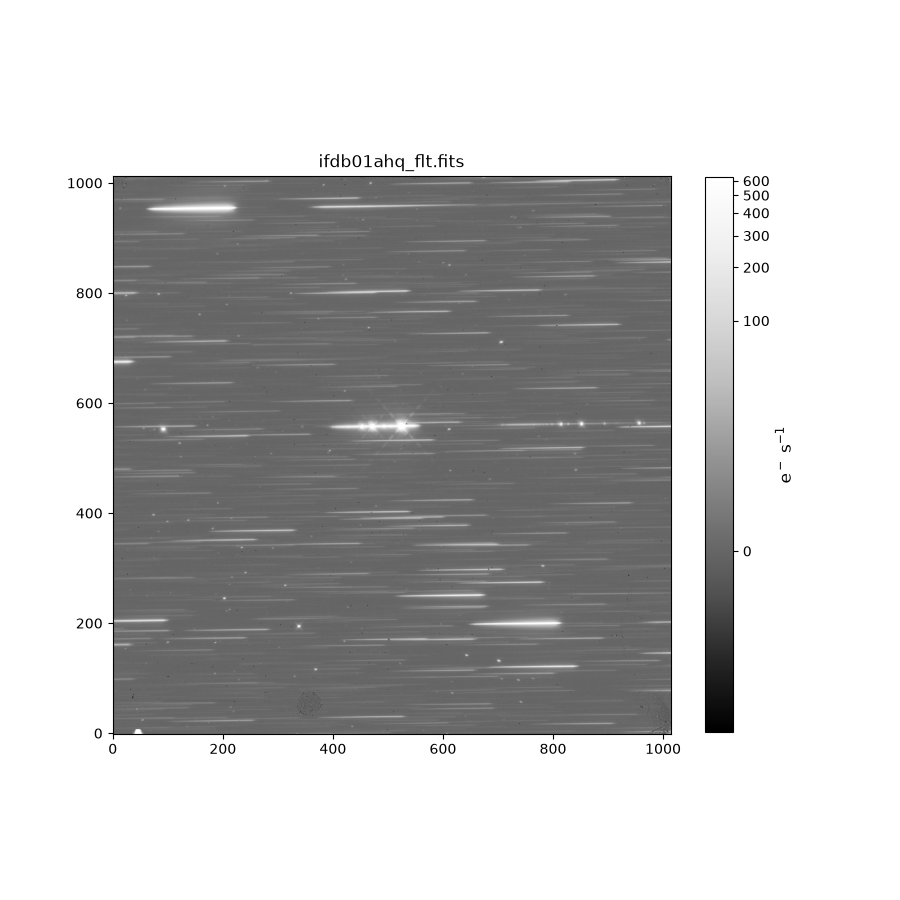

In [13]:
fig, axs = plt.subplots(1, 1, figsize=(9, 9))
img = fits.getdata(f'{DATASETS[GRATING][0]}_flt.fits')
z1, z2 = zscale.get_limits(img)
inorm = ImageNormalize(img, vmin=z1, vmax=z2*100, stretch=LogStretch())
im1 = axs.imshow(img, origin='lower', cmap='Greys_r', norm=inorm)
axs.set_title(f'{DATASETS[GRATING][0]}_flt.fits')
fig.colorbar(im1, ax=axs, shrink=0.8).set_label(label='e$^-$ s$^{-1}$', size=12)
plt.show()

<a id="checkwcs"></a>
### 4.2 Check the World Coordinate System (WCS) 

It is likely that the active WCS in the direct and grism images differ. <b>Having a consistent astrometric reference for the direct<br>
and grism images is crucial for successful spectral extraction</b>. In this section, we will investigate the active WCS (header <br>
keyword `WCSNAME`) and ultimately use `slitlessutils` to change the WCS of the direct images. We start by using <br>
`slitlessutils` to display the active WCS of the direct and grism images. 

For more information about `slitlessutils` astrometry, see the [documentation](https://slitlessutils.readthedocs.io/en/latest/astrometry.html). For a more technical and detailed understanding <br>
of HST WCS and improved absolute astrometry please see [WFC3 ISR 2022-06](https://ui.adsabs.harvard.edu/abs/2022wfc..rept....6M/abstract) (Mack et al.). A general overview is also available on <br>[Outerspace](https://outerspace.stsci.edu/pages/viewpage.action?spaceKey=HAdP&title=Improvements+in+HST+Astrometry).


In [14]:
os.chdir(cwd)
su.core.preprocess.astrometry.list_wcs(f'{GRATING.lower()}/i*flt.fits')
su.core.preprocess.astrometry.list_wcs(f'{FILTER.lower()}/i*flt.fits')

 g102/ifdb01akq_flt.fits                     G102
+----------+--------------------------------+--------------------------------+
| WCSVERS  |                              1 |
+----------+--------------------------------+--------------------------------+
| WCSNAME  |           IDC_w3m18525i-GSC240 | 
| WCSNAMEA |                  IDC_w3m18525i | 
| WCSNAMEB |           IDC_w3m18525i-GSC240 | 
| WCSNAMEO |                           OPUS | 
+----------+--------------------------------+--------------------------------+


 g102/ifdb01anq_flt.fits                     G102
+----------+--------------------------------+--------------------------------+
| WCSVERS  |                              1 |
+----------+--------------------------------+--------------------------------+
| WCSNAME  |           IDC_w3m18525i-GSC240 | 
| WCSNAMEA |                  IDC_w3m18525i | 
| WCSNAMEB |           IDC_w3m18525i-GSC240 | 
| WCSNAMEO |                           OPUS | 
+----------+-----------------------

<br>

As shown above, the F105W active WCS (<em>IDC_w3m18525i-FIT_IMG_GAIAeDR3</em>) is <b>different</b> from the G102 active WCS <br>
(<em>IDC_w3m18525i-GSC240</em>). The F105W images have an undistorted <em>a posteriori</em> solution with a WCS that has been matched to<br>
the Gaia Early Data Release 3 (eDR3) reference catalog using stars from the images. <em>'IMG'</em> denotes that each FLT exposure was<br>
separately aligned to the reference catalog. The G102 images, on the other hand, have an undistorted <em>a priori</em> solution where  <br>
guide star coordinates are corrected from the original reference frame to the Gaia DR1-based Guide Star Catalog v2.4.0 (GSC240). 

To fix the discrepancy, we will use `slitlessutils` to "downgrade" the WCS of the direct images to match the grism images. <br>
The WCS solution we want (<em>IDC_w3m18525i-GSC240</em>) is encoded in the header keyword `WCSNAMEB` of the F105W images.

In [15]:
direct_imgs = [f'{FILTER.lower()}/{direct}_flt.fits' for direct in DATASETS[FILTER]]
for img in direct_imgs:
    su.core.preprocess.astrometry.downgrade_wcs(img, key='B', inplace=True) # `key` corresponds to WCS in WCSNAMEB

INFO MainProcess> downgrading WCS in f105w/ifdb01agq_flt.fits to WCSNAMEB


INFO MainProcess> downgrading WCS in f105w/ifdb01ajq_flt.fits to WCSNAMEB


INFO MainProcess> downgrading WCS in f105w/ifdb01amq_flt.fits to WCSNAMEB


<br>
Finally, we print the active WCS names one last time to verify the upgrade worked as intended. 

In [16]:
files = glob.glob(f'{FILTER.lower()}/i*_flt.fits')+glob.glob(f'{GRATING.lower()}/i*_flt.fits')
for f in files:
    print(f, fits.getval(f, 'WCSNAME', ext=1))

f105w/ifdb01agq_flt.fits IDC_w3m18525i-GSC240-1
f105w/ifdb01amq_flt.fits IDC_w3m18525i-GSC240-1
f105w/ifdb01ajq_flt.fits IDC_w3m18525i-GSC240-1
g102/ifdb01akq_flt.fits IDC_w3m18525i-GSC240
g102/ifdb01anq_flt.fits IDC_w3m18525i-GSC240
g102/ifdb01ahq_flt.fits IDC_w3m18525i-GSC240


<a id="direct"></a>
## 5. Preprocess the F105W Direct Images 

With the grism data calibrated and a consistent WCS across all images, we can proceed to preprocessing the direct images. <br>
The two main steps we need to complete are <b>(1) drizzling the direct images</b> together and <b>(2) creating a segmentation map.</b> 

Information about DrizzlePac can be found [on the STScI website](https://www.stsci.edu/scientific-community/software/drizzlepac), and AstroDrizzle
tutorials are hosted in the [hst_notebooks](https://github.com/spacetelescope/hst_notebooks/tree/main/notebooks/DrizzlePac) <br>GitHub repo.

In [17]:
def preprocess_direct(datasets, filt, root, scale, ra, dec, rad, telescope, instrument):
    """
    Function to create a drizzle image and segmentation map for direct image data.

    Parameters
    ----------
    datasets : dict
        A dictionary of grism and filter rootnames
    filt : str
        The direct image filter associated with datasets e.g. F200LP
    root : str
        The filename for the drizzle image and seg. map
    scale : float
        Pixel (plate) scale for drizzle image and seg. map (arcsec)
    ra : float
        The Right Ascension of the source in the direct image (degrees)
    dec : float
        The Declination of the source in the direct image (degrees)
    rad : float
        The radius of the segmentation size (arcsec)
    telescope : str
        The name of the observatory; e.g. HST
    instrument : str
        The name of the instrument; e.g. WFC3

    Outputs
    -------
    Drizzle image : FITS file
        <root>_drz_sci.fits
    Segmentation map : FITS file
        <root>_drz_seg.fits
    """

    files = [f'{imgdset}_flt.fits' for imgdset in datasets[filt]]

    # mosaic data via astrodrizzle
    astrodrizzle.AstroDrizzle(files, output=root, build=False,
                              static=False, skysub=False, driz_separate=False,
                              median=False, blot=False, driz_cr=False,
                              driz_combine=True, final_wcs=True,
                              final_rot=0., final_scale=scale,
                              final_pixfrac=1.0,
                              overwrite=True, final_fillval=0.0)

    # Must use memmap=False to force close all handles and allow file overwrite
    with fits.open(f'{root}_drz_sci.fits', memmap=False) as hdulist:
        img = hdulist['PRIMARY'].data
        hdr = hdulist['PRIMARY'].header

    wcs = WCS(hdr)
    x, y = wcs.all_world2pix(ra, dec, 0)
    
    xx, yy = np.meshgrid(np.arange(hdr['NAXIS1']),
                         np.arange(hdr['NAXIS2']))
    rr = np.hypot(xx-x, yy-y)
    seg = rr < (rad/scale)
    
    # add some keywords for SU
    hdr['TELESCOP'] = telescope
    hdr['INSTRUME'] = instrument
    hdr['FILTER'] = filt

    # write the files to disk
    fits.writeto(f'{root}_drz_sci.fits', img, hdr, overwrite=True)
    fits.writeto(f'{root}_drz_seg.fits', seg.astype(int), hdr, overwrite=True)

In [18]:
os.chdir(FILTER.lower())
preprocess_direct(DATASETS, FILTER, ROOT, SCALE, RA, DEC, RAD, TELESCOPE, INSTRUMENT)

Setting up logfile :  astrodrizzle.log


WCS Keywords


Number of WCS axes: 2


CTYPE : 'RA---TAN' 'DEC--TAN'


CUNIT : 'deg' 'deg'


CRVAL : 291.0983139188943 9.904157606520858


... (12 outputs left out)

NAXIS : 1743  1827


Writing out image to disk: WFC3_IR_VY2-2_drz_sci.fits


Writing out image to disk: WFC3_IR_VY2-2_drz_wht.fits


Writing out image to disk: WFC3_IR_VY2-2_drz_ctx.fits


<a id="drizzle"></a>
### 5.1 Display Drizzle Image and Overlay Segmentation Map

Next, we display the F105W drizzle image created in the cell above. We also overplot the segmentation map by getting all<br>
the x and y pixels where the segmentation array is `True`. Visually inspect the drizzle science image (and other drizzle <br>
products if needed) for accurate image alignment and combination, as well as the source location as defined by the<br>
segmentation map. <b>Note</b>, if you are using your own datasets with this notebook and  the segmentation map does not line <br>
up with the underlying source, you may need to adjust the `RA` and `DEC` variables.

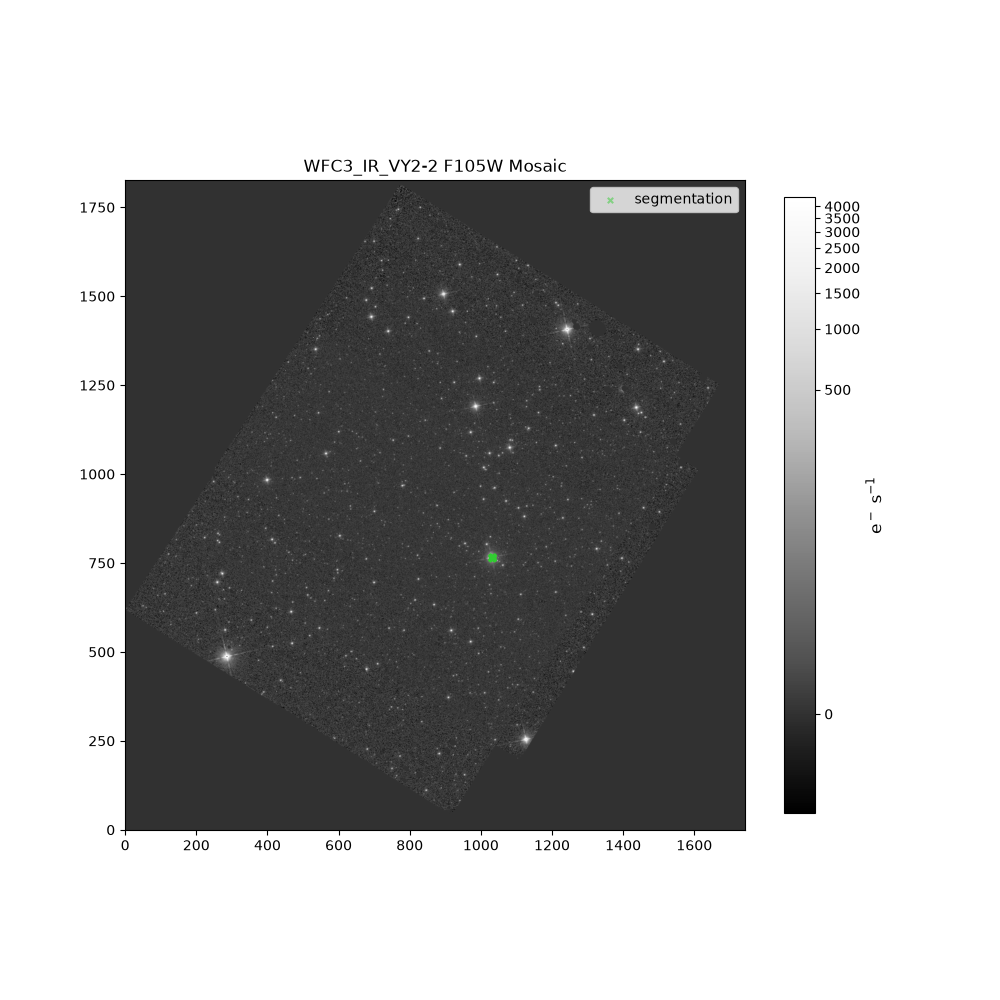

In [19]:
# get drizzle data
d = fits.getdata(f'{ROOT}_drz_sci.fits')
# get seg map coordinates
y, x = np.where(fits.getdata(f'{ROOT}_drz_seg.fits') == 1)

# display the image and seg map coords
fig, axs = plt.subplots(1, 1, figsize=(10, 10))
z1, z2 = zscale.get_limits(d[600:950, 850:1200])
inorm = ImageNormalize(d, vmin=z1, vmax=z2*200, stretch=LogStretch())
im1 = axs.imshow(d, origin='lower', cmap='Greys_r', norm=inorm)
axs.scatter(x, y, 15, marker='x', c='limegreen', alpha=0.5, label='segmentation')
fig.colorbar(im1, ax=axs, shrink=0.8).set_label(label='e$^-$ s$^{-1}$', size=12)
axs.set_title(f'{ROOT} {FILTER} Mosaic')
axs.legend()
plt.show()

<a id="extract"></a>
## 6. Extract the Spectrum from the Grism Data 

We are now finished with all the preprocessing steps and ready to extract the 1D spectrum. The function below, `extract_single()`, <br>
demonstrates a complete single-orientation spectral extraction workflow using `slitlessutils`, starting from calibrated WFC3/IR <br>
grism exposures and a direct-image-based source catalog (segmentation map). Below, we list each of the core `slitlessutils` tasks <br>
used in `extract_single()` and provide a brief description of what the task does.

- `WFSSCollection` serves as a container for the grism FLT exposures used in the extraction. Grouping them into a collection allows<br>
the software to treat the set of exposures as a unified dataset when projecting sources, building pixel‑dispersion tables (PDTs), and<br>
performing extraction. For more information about `WFSSCollection`, see the [documentation](https://slitlessutils.readthedocs.io/en/latest/wfss.html).

- `SourceCollection` is a similar container data structure that defines the sources from the inputted segmentation map and the <br>
drizzled science image; both made from the associated direct filter data. For more information about `SourceCollection`, see <br>
the [documentation](https://slitlessutils.readthedocs.io/en/latest/sources.html).

- `Region` is a module that creates visual outlines of where each source’s dispersed light appears on the grism images. It does this<br>
by reading the PDTs and distilling them into [DS9](https://sites.google.com/cfa.harvard.edu/saoimageds9)‑compatible region files that trace the footprint of each spectral order across the <br>
detector. These region files are not required for extraction, but are useful for quickly inspecting which parts of the grism images <br>
contribute to each object’s spectrum. More information about `Region` can be found in the [documentation](https://slitlessutils.readthedocs.io/en/latest/regions.html).

- `Tabulate` performs the forward‑modeling step that connects the direct image to the grism frames. For every relevant direct‑image <br>
pixel, it computes the trace, wavelength mapping, and fractional pixel coverage and stores the results in a PDT. Because this calculation <br>
is computationally expensive, `slitlessutils` only computes PDTs when requested and then saves them in hierarchical data-format<br>
5 (HDF5) files inside the `su_tables/` directory for later use. The PDT files only capture the geometric mapping of the scene. <br>
Instrumental effects and the actual astrophysical signal are added later in the workflow, so the PDTs depend solely on the WCS and its<br>
calibration. See the `Tabulate` [documentation](https://slitlessutils.readthedocs.io/en/latest/tabulation.html) for more information.

- `Single` is the class that carries out the one‑dimensional extraction for a <em>single</em> telescope orientation (position angle) and spectral <br>
order (here, the +1 order). It uses the PDTs to forward‑model how each direct‑image pixel contributes to the dispersed spectrum and <br>
assembles these contributions into a 1D spectrum. The method is conceptually similar to `HSTaXe`, but with a more flexible contamination<br>
model and a full forward‑modeling approach that can support optimization, such as SED‑fitting workflows. This extraction mode is <br>
intended for relatively simple, isolated sources where self‑contamination is not severe. A given spectral order should be extracted one <br>
at a time. Note, the software will overwrite the `x1d.fits` file, so users must use unique file names with `root`. For additional details,<br>
see the `Single` [documentation](https://slitlessutils.readthedocs.io/en/latest/single.html).

<b>Note</b>, the AB mag zeropoint for the direct image filter (here, F105W) is needed for `SourceCollection`. It is used by `slitlessutils`<br>
to measure the magnitude within the aperture, which allows users to reject sources that are too faint. The value used for zeropoint will not <br>
affect the resulting spectrum. Zeropoints for WFC3/IR filters are available at the [WFC3/IR Photometric Calibration page](https://www.stsci.edu/hst/instrumentation/wfc3/data-analysis/photometric-calibration/ir-photometric-calibration). For convenience, <br>
a table of zeropoints for common filters is provided below. These zeropoints were created using the [`stsynphot`](https://stsynphot.readthedocs.io/en/latest/index.html) Python package with an <br>
`obsmode` of `'wfc3, ir, {filter}, mjd#60744, aper#6'`. For the most accurate and time-dependent zeropoints, we recommend <br>
using `stsynphot`. A tutorial for calculating WFC3 time-dependent zeropoints with `stsynphot` is available as a
 [Jupyter notebook](https://spacetelescope.github.io/hst_notebooks/notebooks/WFC3/zeropoints/zeropoints.html#) (see<br>
 [Section 5](https://spacetelescope.github.io/hst_notebooks/notebooks/WFC3/zeropoints/zeropoints.html#zps) of that tutorial). 

<table style="margin-left: 0; margin-right: auto; border-collapse: collapse;">
  <thead>
    <tr>
      <th style="text-align: left; padding: 6px;">Filter</th>
      <th style="text-align: left; padding: 6px;">Approximate AB Mag Zeropint</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 6px;">F098M</td>
      <td style="padding: 6px;">25.650</td>
    </tr>
    <tr>
      <td style="padding: 6px;">F105W</td>
      <td style="padding: 6px;">26.246</td>
    </tr>
    <tr>
      <td style="padding: 6px;">F140W</td>
      <td style="padding: 6px;">26.445</td>
    </tr>
    <tr>
      <td style="padding: 6px;">F160W</td>
      <td style="padding: 6px;">25.938</td>
    </tr>
  </tbody>
</table>


In [20]:
def extract_single(grating, filt, root, zeropoint, tabulate=False):
    """
    Basic single orient extraction similar to HSTaXe

    Parameters
    ----------
    grating : str 
        The grism image filter associated with datasets; e.g. G280
    filt : str
        The direct image filter associated with datasets e.g. F200LP
    root : str 
        The rootname of the drz and seg FITS file; will also be the 1d spectrum output file rootname
    zeropoint : float
        The AB mag zeropoint of the direct image filter; needed when simulating or rejecting faint sources
    tabulate : Bool
        If true, SU computes the pixel‑dispersion tables. Only need PDTs once per `data` and `sources`

    Output
    ------
    1D spectrum : FITS file
        root_x1d.fits
    
    """
    # load grism data into slitlessutils
    data = su.wfss.WFSSCollection.from_glob(f'../{grating.lower()}/*_flt.fits')

    # load the sources from direct image into slitlessutils
    sources = su.sources.SourceCollection(f'../{filt.lower()}/{root}_drz_seg.fits',
                                          f'../{filt.lower()}/{root}_drz_sci.fits',
                                          local_back=False,
                                          zeropoint=zeropoint)
    
    # create region files for spectral orders
    # regions are not required for spectral extraction
    reg = su.modules.Region(ncpu=1)
    reg(data, sources) 

    # project the sources onto the grism images; output to `su_tables/`
    if tabulate:
        tab = su.modules.Tabulate(ncpu=1)
        tab(data, sources)

    # run a single-orient extraction on the +1 order
    ext = su.modules.Single('+1', mskorders=None, root=root, ncpu=1)
    ext(data, sources, profile='uniform', width=15)

In [21]:
os.chdir('../output')
extract_single(GRATING, FILTER, ROOT, ZEROPOINT, tabulate=True)

INFO MainProcess> Loading from glob: ../g102/*_flt.fits


INFO MainProcess> Loading WFSS data from python list


INFO MainProcess> loading throughput from keys: ('hst', 'wfc3', 'f105w')


INFO MainProcess> Loading a classic segmentation map: ../f105w/WFC3_IR_VY2-2_drz_seg.fits


INFO MainProcess> Serial processing


Regions:   0%|          | 0/3 [00:00<?, ?it/s]

... (15 outputs left out)

Extracting (single): 100%|██████████| 3/3 [00:00<00:00,  5.46it/s]

Extracting (single): 100%|██████████| 3/3 [00:00<00:00,  5.42it/s]

INFO MainProcess> Combining the 1d spectra


INFO MainProcess> Writing: /home/runner/work/hst_notebooks/hst_notebooks/notebooks/WFC3/slitlessutils_IR_extraction/output/WFC3_IR_VY2-2_x1d.fits


<br>

<a id="region"></a>
### 6.1 Display a Region File

Below, we display a grism FLT file and the associated region file. The region files are useful for quickly inspecting which part <br>
of the grism image contribute to each object’s spectrum. The 0, <span style="color: blue;"><b>+1</b></span>, <span style="color: orange;"><b>+2</b></span>, and <span style="color: green;"><b>+3</b></span> spectral orders for the observations are outlined <br>
in white, blue, orange, and green, respectively. More information about the `slitlessutils` region files can be found in the <br>[documentation](https://slitlessutils.readthedocs.io/en/latest/regions.html). 

<b>Note</b>: if the figure below does not display correctly, try switching to `%matplotlib inline`.  

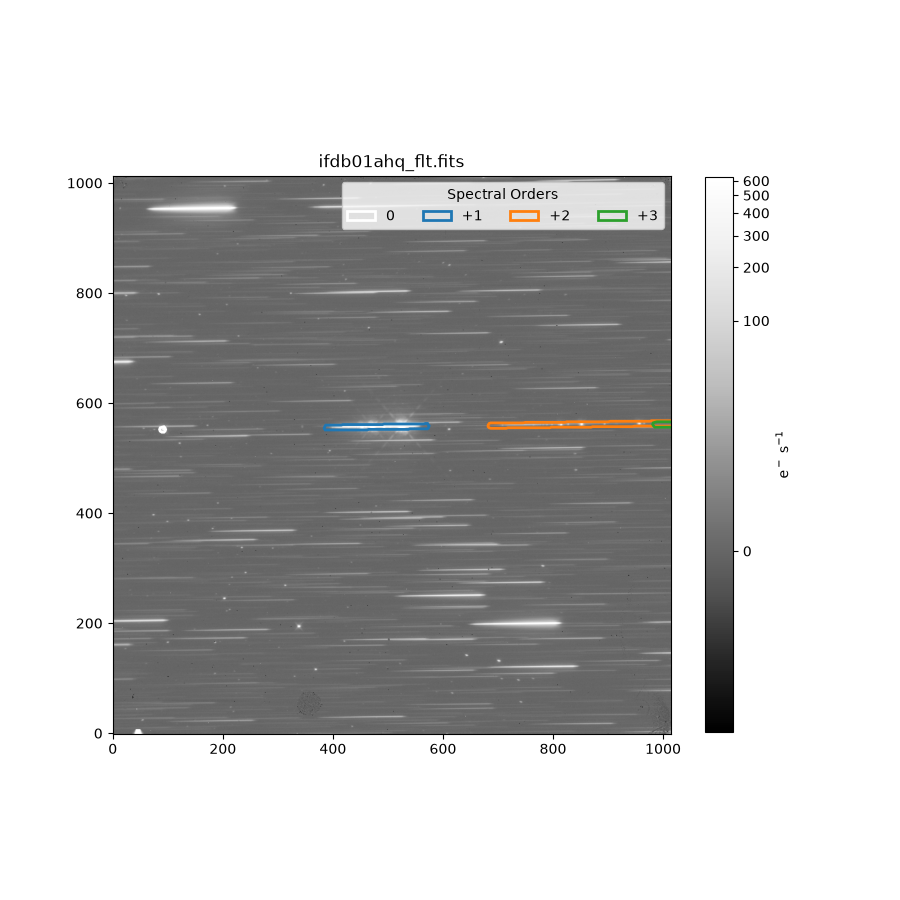

In [22]:
# %matplotlib inline
i = 0 # which FLT image to display
fig, axs = plt.subplots(1, 1, figsize=(9, 9))

# Display a grism FLT
flt = fits.getdata(f'../{GRATING.lower()}/{DATASETS[GRATING][i]}_flt.fits')
z1, z2 = zscale.get_limits(flt)
inorm = ImageNormalize(flt, vmin=z1, vmax=z2*100, stretch=LogStretch())
im1 = axs.imshow(flt, origin='lower', cmap='Greys_r', norm=inorm)
axs.set_title(f'{DATASETS[GRATING][i]}_flt.fits')
fig.colorbar(im1, ax=axs, shrink=0.8, label='e$^-$ s$^{-1}$')

# Display the corresponding region file
region = pyregion.open(f'{DATASETS[GRATING][i]}_IR.reg')
patch_list, _ = region.get_mpl_patches_texts()
orders = ['+1', '0', '+2', '+3']
# Add patches 
for idx, p in enumerate(patch_list):
    p.set_linewidth(2)
    p.set_label(orders[idx])
    axs.add_patch(p)
# Reorder legend numerically 
handles, labels = axs.get_legend_handles_labels()
sorted_pairs = sorted(zip(handles, labels), key=lambda x: int(x[1].replace('+','')))
handles_sorted, labels_sorted = zip(*sorted_pairs)
axs.legend(handles_sorted, labels_sorted, title="Spectral Orders", ncol=4)
plt.show()

<br>

<a id="plot"></a>
### 6.2 Plot the Spectrum

Finally, what we've all been waiting for(!), plotting the extracted spectrum. The `Single` module produces a single spectrum for each <br>
source and grism image. Those spectra are then combined into a single one-dimensional spectrum for each source and saved as a<br>
`x1d.fits` file. In this example, we only have one source, so there is a single spectrum.<br>

The `x1d` file is a binary table with columns for the wavelength (`WAVELENGTH`), flux (`FLUX`), uncertainty (`UNCERTAINTY`), contamination<br>
(`CONTAMINATION`), and number of pixels (`NMEASUREMENTS`). By default [configuration](https://slitlessutils.readthedocs.io/en/latest/configure.html#global-variables-config), the flux and uncertainty values are in units of <br>
<em>erg s<sup>-1</sup> cm<sup>-2</sup> · Å<sup>-1</sup></em> and scaled by 10<sup>-17</sup> (`cfg.fluxunits` and `cfg.fluxscale`).

There are several emission lines in VY2-2's spectrum. A list of emission lines is provided in Table 2 of [WFC3 ISR 2015-10](https://www.stsci.edu/files/live/sites/www/files/home/hst/instrumentation/wfc3/documentation/instrument-science-reports-isrs/_documents/2015/WFC3-2015-10.pdf) (Bohlin et al.), <br>
which has been copied over to this notebook in the cell below.



In [23]:
cfg.fluxunits, cfg.fluxscale

('erg / (s * cm**2 * Angstrom)', 1e-17)

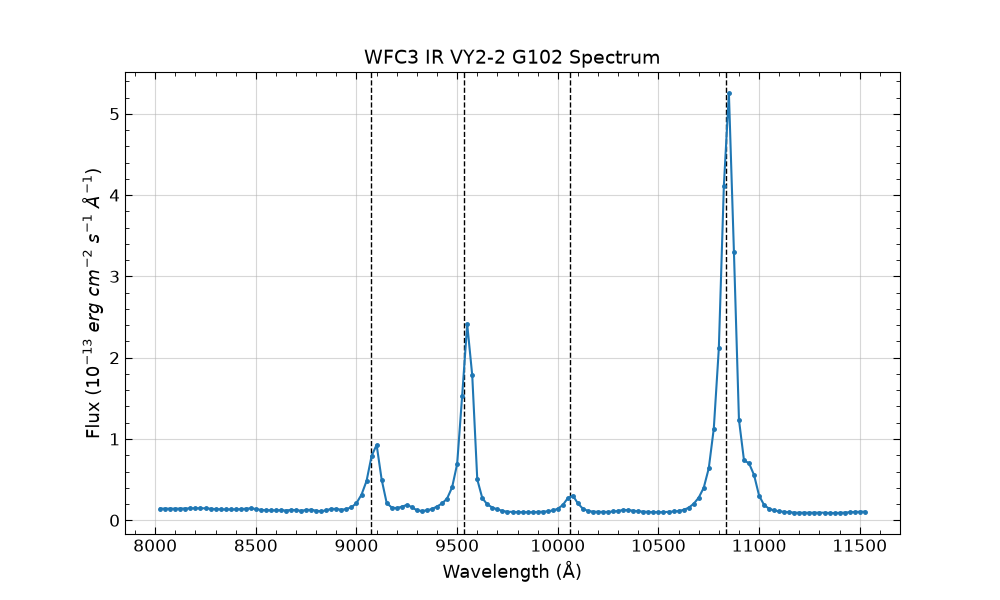

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.grid(alpha=0.5)

# load spectrum
dat = fits.getdata(f'{ROOT}_x1d.fits')

# create wavelength mask
lrange = (8000, 11550) 
wav = (lrange[0] < dat['WAVELENGTH']) & (dat['WAVELENGTH'] < lrange[1])

# plot spectrum
ax.errorbar(dat['WAVELENGTH'][wav], 
            dat['FLUX'][wav]*cfg.fluxscale/1e-13, 
            yerr=dat['UNCERTAINTY'][wav]*cfg.fluxscale/1e-13, 
            marker='.', markersize=5)

# overlay known emission lines
ax.axvline(9070, ls='--', c='k', lw=1)  # [SIII]; S²⁺
ax.axvline(9535, ls='--', c='k', lw=1)  # [SIII]; S²⁺ blended with H I Pε
ax.axvline(10060, ls='--', c='k', lw=1) # H I P7; n = 7 → 3
ax.axvline(10834, ls='--', c='k', lw=1) # He I; 2³S → 2³P

# matplotlib formatting
ax.minorticks_on()
ax.yaxis.set_ticks_position('both'), ax.xaxis.set_ticks_position('both')
ax.tick_params(axis='both', which='minor', direction='in', labelsize=12, length=3)
ax.tick_params(axis='both', which='major', direction='in', labelsize=12, length=5)
ax.set_xlabel(r'Wavelength ($\mathrm{\AA}$)', size=13)
ax.set_ylabel(r'Flux ($10^{-13}\ erg\ cm^{-2}\ s^{-1}\ \AA^{-1}$)', size=13)
ax.set_title(f"{ROOT.replace('_', ' ')} {GRATING} Spectrum", size=14)
plt.show()

<a id="conclusions"></a>
## 7. Conclusions 

Thank you for going through this notebook. You should now have all the necessary tools to extract a 1D spectrum from WFC3<br>
IR grism data using `slitlessutils`. After completing this notebook, you should be more familiar with:
- Downloading data from MAST.
- Performing background subtraction using WFC3 Backsub.
- Preprocessing images for `slitlessutils`.
- Creating and displaying region files.
- Extracting and plotting a source's spectrum.

<a id="add"></a>
## Additional Resources 

Below are some additional resources that may be helpful. Please send any questions through the [HST Help Desk](https://stsci.service-now.com/hst).

- [WFC3 Website](https://www.stsci.edu/hst/instrumentation/wfc3)
- [WFC3 Grism Resources](https://www.stsci.edu/hst/instrumentation/wfc3/documentation/grism-resources)
- [WFC3 Instrument Handbook](https://hst-docs.stsci.edu/wfc3ihb)
- [WFC3 Data Handbook](https://hst-docs.stsci.edu/wfc3dhb)


<a id="about"></a>
## About this Notebook 

**Author:** Benjamin Kuhn, WFC3 Team <br>
**Last Updated:** 2026-03-25<br>
**Created** 2026-01-15

<a id="cite"></a>
## Citations 
If you use Python packages for published research, please cite the authors. <br>
Follow these links for more information about citing packages used in this notebook:

* [Citing `astropy`](https://www.astropy.org/acknowledging.html)
* [Citing `astroquery`](https://github.com/astropy/astroquery/blob/main/astroquery/CITATION)
* [Citing `drizzlepac`](https://drizzlepac.readthedocs.io/en/latest/getting_started/citing_drizzlepac.html#citing-drizzlepac)
* [Citing `matplotlib`](https://matplotlib.org/stable/project/citing.html)
* [Citing `numpy`](https://www.scipy.org/citing.html#numpy)
* [Citing `slitlessutils`](https://slitlessutils.readthedocs.io/en/latest/citation.html) 
***

[Top of Page](#top)
<img style="float: right;" src="https://raw.githubusercontent.com/spacetelescope/hst_notebooks/main/assets/stsci_pri_combo_mark_horizonal_white_bkgd.png" alt="Space Telescope Logo" width="200px\"/>